# Plant Pathology 2020 - Elma Yaprağı Hastalık Sınıflandırması
Önceden eğitilmiş MobileNetV2 ile görüntülerden özellik çıkarma + scikit-learn sınıflandırıcı.

In [1]:
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [2]:
# İndirdiğin veri klasörünün yolu. Notebook ile aynı klasördeyse '.' kalabilir.
# Örnek: DATA_DIR = r'C:\Users\kullanici\Downloads\plant-pathology-2020-fgvc7'
DATA_DIR = '.'
df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
CLASSES = ['healthy', 'multiple_diseases', 'rust', 'scab']
df['label'] = df[CLASSES].values.argmax(axis=1)
print(df.shape)
df.head()

(1821, 6)


,image_id,healthy,multiple_diseases,rust,scab,label
0,Train_0,0,0,0,1,3
1,Train_1,0,1,0,0,1
2,Train_2,1,0,0,0,0
3,Train_3,0,0,1,0,2
4,Train_4,1,0,0,0,0


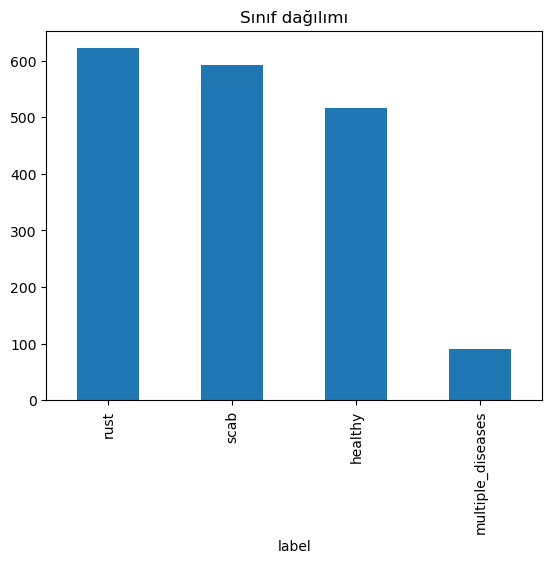

In [3]:
df['label'].map(dict(enumerate(CLASSES))).value_counts().plot(kind='bar', title='Sınıf dağılımı')
plt.show()

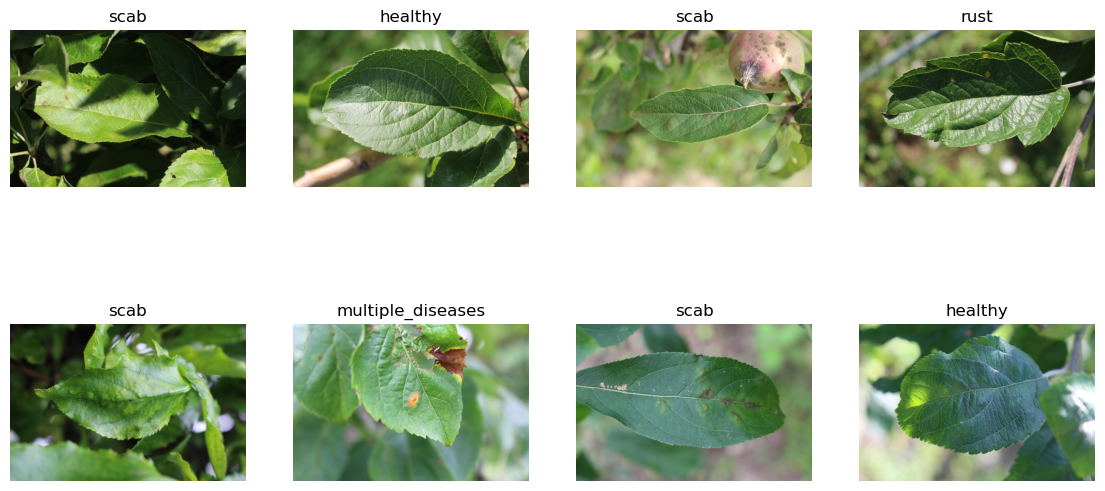

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, row) in zip(axes.ravel(), df.sample(8, random_state=1).iterrows()):
    ax.imshow(Image.open(os.path.join(DATA_DIR, 'images', row['image_id'] + '.jpg')))
    ax.set_title(CLASSES[row['label']]); ax.axis('off')
plt.show()

In [5]:
extractor = MobileNetV2(weights='imagenet', include_top=False, pooling='avg', input_shape=(224, 224, 3))

def load_img(path):
    img = Image.open(path).convert('RGB').resize((224, 224))
    return np.array(img, dtype=np.float32)

def extract(paths, batch=32):
    feats = []
    for i in range(0, len(paths), batch):
        x = np.stack([load_img(p) for p in paths[i:i+batch]])
        feats.append(extractor.predict(preprocess_input(x), verbose=0))
    return np.vstack(feats)

paths = [os.path.join(DATA_DIR, 'images', i + '.jpg') for i in df['image_id']]
X = extract(paths)
y = df['label'].values
X.shape

(1821, 1280)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

models = {
    'LogisticRegression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'RandomForest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print(name, 'doğruluk:', round(accuracy_score(y_test, m.predict(X_test)), 4))

LogisticRegression doğruluk: 0.8329
RandomForest doğruluk: 0.7973


                   precision    recall  f1-score   support

          healthy       0.79      0.91      0.85       103
multiple_diseases       0.29      0.22      0.25        18
             rust       0.91      0.86      0.88       125
             scab       0.87      0.83      0.85       119

         accuracy                           0.83       365
        macro avg       0.71      0.71      0.71       365
     weighted avg       0.83      0.83      0.83       365



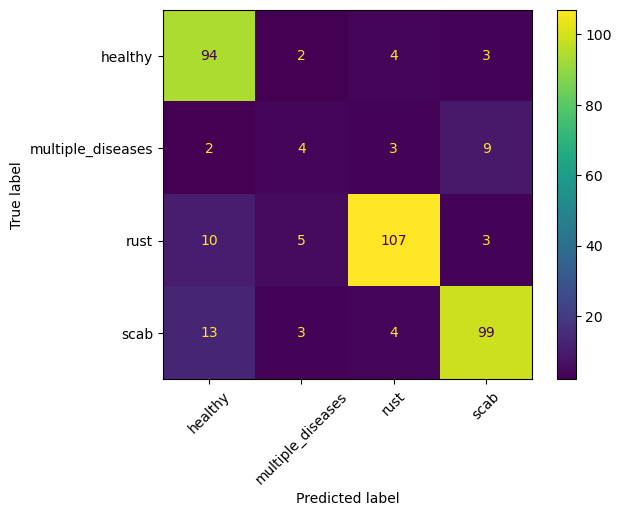

In [7]:
best = models['LogisticRegression']
pred = best.predict(X_test)
print(classification_report(y_test, pred, target_names=CLASSES))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=CLASSES).plot(xticks_rotation=45)
plt.show()

In [8]:
with open('model.pkl', 'wb') as f:
    pickle.dump(best, f)
print('model.pkl kaydedildi')

model.pkl kaydedildi


In [ ]:
test = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
Xt = extract([os.path.join(DATA_DIR, 'images', i + '.jpg') for i in test['image_id']])
proba = best.predict_proba(Xt)
sub = pd.DataFrame(proba, columns=CLASSES)
sub.insert(0, 'image_id', test['image_id'])
sub.to_csv('submission.csv', index=False)
sub.head()

Bu projede elma yapraklarındaki hastalıklar (sağlıklı, birden fazla hastalık, pas, kabuklanma) MobileNetV2 ile çıkarılan özellikler üzerinde Logistic Regression ve Random Forest modelleriyle sınıflandırıldı. En iyi sonucu [model adı] modeli %[X] doğrulukla verdi. Model, az örneği olan multiple_diseases sınıfında diğerlerine göre daha zayıf kaldı. 